In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss

df = pd.read_csv("../data/processed/features_v2.csv", parse_dates=["GAME_DATE"])

old_feats = ["HOME_PTS_ROLL10", "HOME_PTS_ALLOWED_ROLL10", "HOME_WIN_ROLL10", "HOME_REST_DAYS",
             "AWAY_PTS_ROLL10", "AWAY_PTS_ALLOWED_ROLL10", "AWAY_WIN_ROLL10", "AWAY_REST_DAYS"]
lr_feats = old_feats + ["ELO_DIFF"]
target_col = "HOME_WIN"

assert "HOME_PTS" not in lr_feats and "AWAY_PTS" not in lr_feats
assert target_col not in lr_feats

usable = df.dropna(subset=lr_feats)

val_start = pd.Timestamp("2021-08-01")
test_start = pd.Timestamp("2022-08-01")
train = usable[usable["GAME_DATE"] < val_start]
val = usable[(usable["GAME_DATE"] >= val_start) & (usable["GAME_DATE"] < test_start)]
test = usable[usable["GAME_DATE"] >= test_start]

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
model.fit(train[lr_feats], train[target_col])

val_p = model.predict_proba(val[lr_feats])[:, 1]
test_p = model.predict_proba(test[lr_feats])[:, 1]
y_val = val[target_col].to_numpy()
y_test = test[target_col].to_numpy()

print("Games - train:", len(train), "| val:", len(val), "| test:", len(test))
print(f"Val log loss  {log_loss(y_val, val_p):.4f}")
print(f"Test log loss {log_loss(y_test, test_p):.4f}")

Games - train: 6981 | val: 1230 | test: 3685
Val log loss  0.6334
Test log loss 0.6196


In [3]:
def reliability_table(y, p, n_bins):
    t = pd.DataFrame({"y": y, "p": p})
    t["bin"] = pd.qcut(t["p"], n_bins, duplicates="drop")
    g = t.groupby("bin", observed=True).agg(
        games=("y", "size"), predicted=("p", "mean"), actual=("y", "mean"))
    g["gap"] = g["actual"] - g["predicted"]
    g["z"] = g["gap"] / np.sqrt(g["predicted"] * (1 - g["predicted"]) / g["games"])
    return g.reset_index(drop=True)

val_tab = reliability_table(y_val, val_p, 5)
test_tab = reliability_table(y_test, test_p, 10)

print("VALIDATION (2021-22)")
print(val_tab.round(3))
print("\nTEST (2022-25)")
print(test_tab.round(3))

VALIDATION (2021-22)
   games  predicted  actual    gap      z
0    246      0.305   0.297 -0.008 -0.284
1    246      0.474   0.435 -0.039 -1.226
2    246      0.587   0.577 -0.010 -0.320
3    246      0.689   0.650 -0.038 -1.296
4    246      0.810   0.760 -0.050 -1.996

TEST (2022-25)
   games  predicted  actual    gap      z
0    369      0.228   0.225 -0.003 -0.156
1    368      0.347   0.356  0.009  0.367
2    369      0.431   0.436  0.005  0.205
3    368      0.497   0.554  0.057  2.195
4    369      0.549   0.507 -0.042 -1.632
5    368      0.597   0.560 -0.037 -1.445
6    368      0.644   0.649  0.005  0.210
7    369      0.698   0.650 -0.048 -2.010
8    368      0.761   0.788  0.027  1.212
9    369      0.849   0.835 -0.014 -0.769


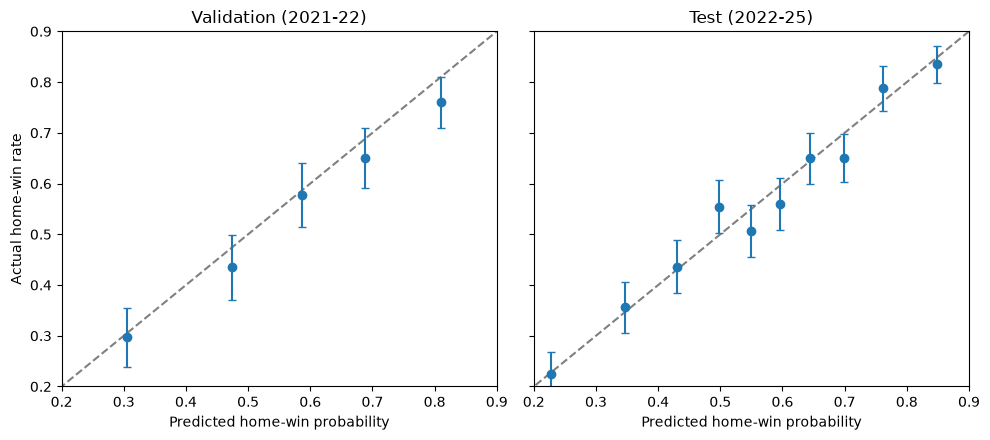

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
panels = ((val_tab, "Validation (2021-22)"), (test_tab, "Test (2022-25)"))

for ax, (tab, title) in zip(axes, panels):
    se = np.sqrt(tab["predicted"] * (1 - tab["predicted"]) / tab["games"])
    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.errorbar(tab["predicted"], tab["actual"], yerr=2 * se, fmt="o", capsize=3)
    ax.set_title(title)
    ax.set_xlabel("Predicted home-win probability")

axes[0].set_ylabel("Actual home-win rate")
axes[0].set_xlim(0.2, 0.9)
axes[0].set_ylim(0.2, 0.9)
plt.tight_layout()
plt.show()

In [5]:
def calibration_summary(name, y, p):
    z = np.log(p / (1 - p)).reshape(-1, 1)
    fit = LogisticRegression(C=1e6, max_iter=1000).fit(z, y)
    print(f"{name}: avg predicted {p.mean():.3f} | actual {y.mean():.3f} | "
          f"slope {fit.coef_[0][0]:.2f} | intercept {fit.intercept_[0]:+.2f}")

calibration_summary("Validation", y_val, val_p)
calibration_summary("Test      ", y_test, test_p)

Validation: avg predicted 0.573 | actual 0.544 | slope 0.90 | intercept -0.11
Test      : avg predicted 0.560 | actual 0.556 | slope 0.96 | intercept -0.01


In [6]:
def logit(p):
    return np.log(p / (1 - p)).reshape(-1, 1)

platt = LogisticRegression(C=1e6, max_iter=1000).fit(logit(val_p), y_val)
test_p_platt = platt.predict_proba(logit(test_p))[:, 1]

print(f"Test log loss, raw model:       {log_loss(y_test, test_p):.4f}")
print(f"Test log loss, after Platt fix: {log_loss(y_test, test_p_platt):.4f}")

Test log loss, raw model:       0.6196
Test log loss, after Platt fix: 0.6210
